# EDA 3 — Articles and time: catalogue, popularity, categories, freshness, time of day and recency

Training split only, except section 5 (cold-start articles in validation and test).

In [1]:
from pathlib import Path

import os
import numpy as np
import pandas as pd
import polars as pl            # only for the 70 M-row candidate table; everything small is pandas
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Project root = folder that contains 1_Data_Preparation/processed (run 1_Data_Preparation/clean_and_validate_data.ipynb first)
try:
    from google.colab import drive
    drive.mount("/content/drive")
    ROOT = Path(os.environ.get("NEWSREC_ROOT", "/content/drive/MyDrive/BT4222")).expanduser().resolve()
except ImportError:
    ROOT = next(p for p in [Path.cwd(), Path.cwd().parent] if (p / "1_Data_Preparation" / "processed").exists())
PROCESSED = ROOT / "1_Data_Preparation" / "processed"
FIG_DIR = ROOT / "2_EDA" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid", palette=["#2a78d6", "#eb6834", "#1baf7a", "#eda100"])
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
print("Project root:", ROOT)

Project root: /Users/anhminhhoang/BT4222


In [2]:
imp = pl.read_parquet(PROCESSED / "impressions_train.parquet", columns=["impression_uid", "user_code", "timestamp", "history_len", "slate_len", "n_clicks"])
cand = pl.read_parquet(PROCESSED / "candidates_train.parquet", columns=["impression_uid", "user_code", "timestamp", "news_code", "clicked"])
news = pl.read_parquet(PROCESSED / "news_catalogue.parquet").drop(["title", "abstract", "url", "title_entities", "abstract_entities"])
cat_map = news.select("news_code", pl.col("category").cast(pl.Categorical))
tr = news.filter(pl.col("in_news_train")).to_pandas()          # the training news file, one row per article

n_imp, n_exp, n_clicks = len(imp), len(cand), int(cand["clicked"].sum())
ctr_all = 100 * n_clicks / n_exp
T0 = imp["timestamp"].min()
print("Impressions:", n_imp, "| Exposures:", n_exp, "| Clicks:", n_clicks, f"| CTR {ctr_all:.2f}%")
print("Articles in the training news file:", len(tr), "| shown in a slate:", int((tr.exposures_train > 0).sum()))

Impressions: 1897835 | Exposures: 70314387 | Clicks: 2868998 | CTR 4.08%
Articles in the training news file: 98671 | shown in a slate: 24641


# 1. The article catalogue

* Sports is a third of the catalogue but a tenth of exposures; news, lifestyle and sports together carry half of the exposures. Exposure
  shares are MSN's editorial choice, not demand.
* Titles are short (median **10 words**, 99% within 20). Abstracts have a median of 27 words, are missing for **5.3%** and are bimodal.
  A quarter of articles have no title entity and 12% no entity at all. 117 of 283 subcategories have fewer than ten articles.

**Model Implications**
* Title-first text encoder (20 tokens for titles, 100 for abstracts covers 99%); mask or title fallback for missing abstracts; a text-only path
  next to entity features; embed or merge subcategories rather than one-hot encode them.

               articles  shown  exposures  clicks  articles_pct  exposures_pct  clicks_pct   ctr
category                                                                                        
sports            31183   6932    7299419  353525         31.60          10.38       12.32  4.84
news              29528   6531   19691828  872706         29.93          28.01       30.42  4.43
finance            5712   1501    6764892  251948          5.79           9.62        8.78  3.72
travel             4839   1376    3683732   97069          4.90           5.24        3.38  2.64
lifestyle          4451   1600    7674586  306325          4.51          10.91       10.68  3.99
video              4423   1216    1041566   45191          4.48           1.48        1.58  4.34
foodanddrink       4298   1243    4322932  128409          4.36           6.15        4.48  2.97
weather            4169   1072    1042291   49369          4.23           1.48        1.72  4.74
autos              2994    824

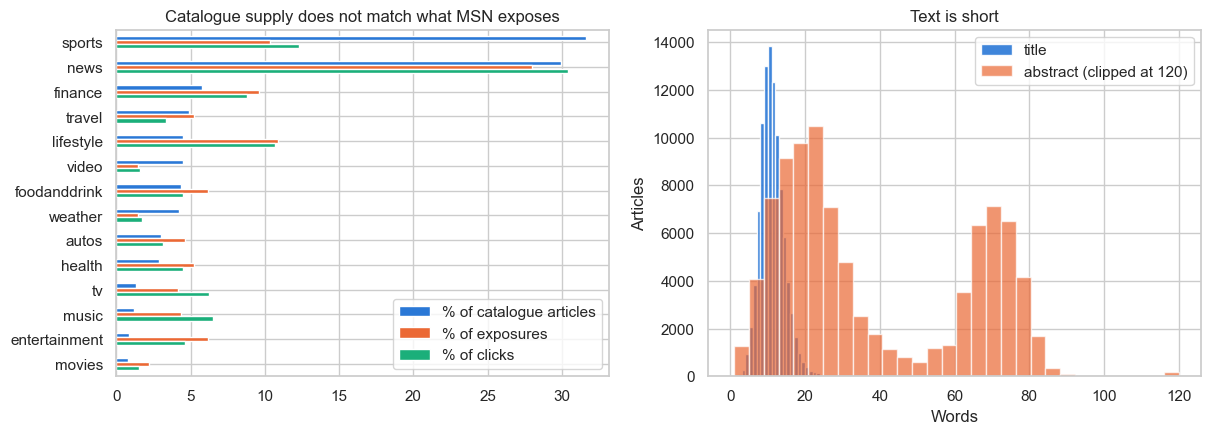

In [3]:
by_cat = tr.groupby("category").agg(articles=("news_code", "size"), shown=("exposures_train", lambda s: int((s > 0).sum())),
                                    exposures=("exposures_train", "sum"), clicks=("clicks_train", "sum"))
for col in ["articles", "exposures", "clicks"]:
    by_cat[col + "_pct"] = 100 * by_cat[col] / by_cat[col].sum()
by_cat["ctr"] = 100 * by_cat.clicks / by_cat.exposures
by_cat = by_cat.sort_values("articles", ascending=False)
print(by_cat.round(2))

sub = tr.subcategory.value_counts()
print(f"\nCategories: {tr.category.nunique()} ({(by_cat.exposures > 0).sum()} ever shown) | subcategories: {len(sub)} ({(sub < 10).sum()} with < 10 articles)")
print(f"Title words: median {tr.title_len_words.median():.0f}, p99 {tr.title_len_words.quantile(.99):.0f} | abstract words (when present): median "
      f"{tr.loc[tr.has_abstract, 'abstract_len_words'].median():.0f}, p99 {tr.abstract_len_words.quantile(.99):.0f} | abstract missing {100 * (1 - tr.has_abstract.mean()):.1f}%")
print(f"Articles with no title entity: {100 * (tr.n_title_entities == 0).mean():.1f}% | no entity at all: {100 * ((tr.n_title_entities + tr.n_abstract_entities) == 0).mean():.1f}%")

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
by_cat.head(14)[["articles_pct", "exposures_pct", "clicks_pct"]].plot(kind="barh", ax=ax[0])
ax[0].invert_yaxis()
ax[0].legend(["% of catalogue articles", "% of exposures", "% of clicks"])
ax[0].set(title="Catalogue supply does not match what MSN exposes", ylabel="")
ax[1].hist(tr.title_len_words, bins=range(0, 31), alpha=.9, label="title")
ax[1].hist(tr.loc[tr.has_abstract, "abstract_len_words"].clip(upper=120), bins=30, alpha=.7, label="abstract (clipped at 120)")
ax[1].set(xlabel="Words", ylabel="Articles", title="Text is short")
ax[1].legend()
plt.savefig(FIG_DIR / "art_01_catalogue.png", dpi=150, bbox_inches="tight")
plt.show()

# 2. Article popularity

One row per article shown in the window: exposures, clicks and CTR over the whole training window (retrospective totals).
* **3% of shown articles collect 80% of clicks** (Gini 0.96); the median article has 46 exposures and one click; 38% of shown articles are
  never clicked.
* Article CTR scatters wildly below a hundred exposures and converges towards the overall 4% as exposure grows.

**Model Implications**
* Popularity is a strong signal but must be **time-causal** (prior exposures, prior clicks, a smoothed prior CTR computed from events before
  the impression). Raw whole-window CTR is neither reliable nor leak-free.

       exposures    clicks       ctr
count   24641.00  24641.00  24641.00
mean     2853.55    116.43      4.11
std     13645.18   1041.88      7.85
min         1.00      0.00      0.00
25%         9.00      0.00      0.00
50%        46.00      1.00      1.78
75%       215.00      8.00      5.17
max    331542.00  60638.00    100.00

747 articles (3.0% of 24,641 shown) account for 80% of clicks | Gini 0.96 | never clicked: 37.9%

By exposure bucket:
           articles  exposures   clicks  never_clicked  exposure_pct   ctr
exposures                                                                 
<10            6223      22113      833          88.41          0.03  3.77
10-99          9488     379506    17715          37.11          0.54  4.67
100-999        5610    1658007    68384           5.81          2.36  4.12
1k-10k         1816    7064831   222415           0.00         10.05  3.15
10k+           1504   61189930  2559651           0.00         87.02  4.18


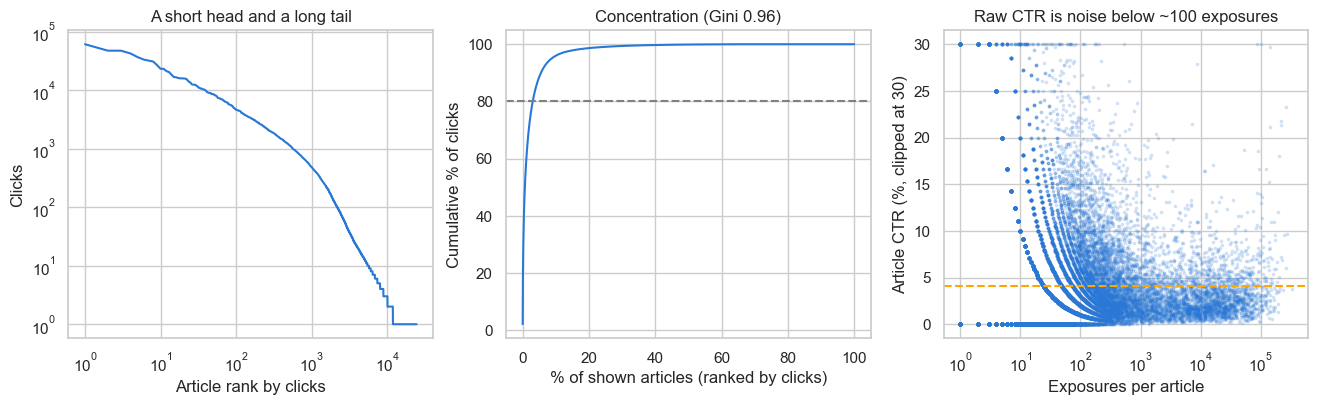

In [4]:
art = tr[tr.exposures_train > 0][["news_code", "category", "exposures_train", "clicks_train"]].rename(columns={"exposures_train": "exposures", "clicks_train": "clicks"})
art["ctr"] = 100 * art.clicks / art.exposures
print(art[["exposures", "clicks", "ctr"]].describe().round(2))

ranked = art.sort_values("clicks", ascending=False).reset_index(drop=True)
cum = 100 * ranked.clicks.cumsum() / ranked.clicks.sum()
n80 = int((cum < 80).sum()) + 1
cl = np.sort(art.clicks.values)
n = len(cl)
gini = 2 * np.sum(np.arange(1, n + 1) * cl) / (n * cl.sum()) - (n + 1) / n
print(f"\n{n80:,} articles ({100 * n80 / n:.1f}% of {n:,} shown) account for 80% of clicks | Gini {gini:.2f} | never clicked: {100 * (art.clicks == 0).mean():.1f}%")

bucket = pd.cut(art.exposures, [0, 9, 99, 999, 9999, 1e9], labels=["<10", "10-99", "100-999", "1k-10k", "10k+"])
pop = art.groupby(bucket, observed=True).agg(articles=("news_code", "size"), exposures=("exposures", "sum"), clicks=("clicks", "sum"), never_clicked=("clicks", lambda s: 100 * (s == 0).mean()))
pop["exposure_pct"] = 100 * pop.exposures / pop.exposures.sum()
pop["ctr"] = 100 * pop.clicks / pop.exposures
print("\nBy exposure bucket:")
print(pop.round(2))

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
ax[0].plot(range(1, n + 1), ranked.clicks.clip(lower=1))
ax[0].set(xscale="log", yscale="log", xlabel="Article rank by clicks", ylabel="Clicks", title="A short head and a long tail")
ax[1].plot(100 * np.arange(1, n + 1) / n, cum)
ax[1].axhline(80, color="grey", ls="--")
ax[1].set(xlabel="% of shown articles (ranked by clicks)", ylabel="Cumulative % of clicks", title=f"Concentration (Gini {gini:.2f})")
ax[2].scatter(art.exposures, art.ctr.clip(upper=30), s=3, alpha=.15)
ax[2].axhline(ctr_all, color="orange", ls="--")
ax[2].set(xscale="log", xlabel="Exposures per article", ylabel="Article CTR (%, clipped at 30)", title="Raw CTR is noise below ~100 exposures")
plt.savefig(FIG_DIR / "art_02_popularity.png", dpi=150, bbox_inches="tight")
plt.show()

# 3. Category engagement

Category is available for every article, including cold-start ones. The risk is confounding: category CTR may only reflect how much exposure
each category's articles received, so the second view compares categories inside exposure buckets.
* Category CTR spans **2.6% (travel) to 6.1% (music, tv)**, and most of the spread survives exposure control: sports stays above its bucket average in
  every bucket, travel, movies, food and drink, finance and lifestyle stay below. Music and tv earn their edge mainly on heavily exposed articles.

**Model Implications**
* Keep `category` as a feature: it survives exposure control, spans a 2.3× range and is one of the few signals for cold-start articles.

               shown  exposures   ctr
category                             
music            367    3054133  6.12
tv               322    2925680  6.10
sports          6932    7299419  4.84
weather         1072    1042291  4.74
news            6531   19691828  4.43
video           1216    1041566  4.34
lifestyle       1600    7674586  3.99
finance         1501    6764892  3.72
health           935    3701912  3.51
entertainment    342    4326965  3.09
northamerica       1        394  3.05
foodanddrink    1243    4322932  2.97
kids              89       2536  2.92
movies           290    1540313  2.87
autos            824    3241208  2.82
travel          1376    3683732  2.64

CTR minus the exposure-bucket average (pp):
bucket         <10  10-99  100-999  1k-10k  10k+
category                                        
music          NaN   -2.0     -0.9    -0.2   2.1
tv             NaN    NaN     -0.7    -0.2   2.1
sports         1.7    1.5      1.5     0.8   0.8
weather        NaN   -0.7 

/var/folders/kz/x1bqw4g54k9bxv6zd2qlrp500000gn/T/ipykernel_36231/3478544780.py:7: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  bucket_avg = cell.groupby("bucket", observed=True).apply(lambda g: 100 * g.clicks.sum() / g.exposures.sum())


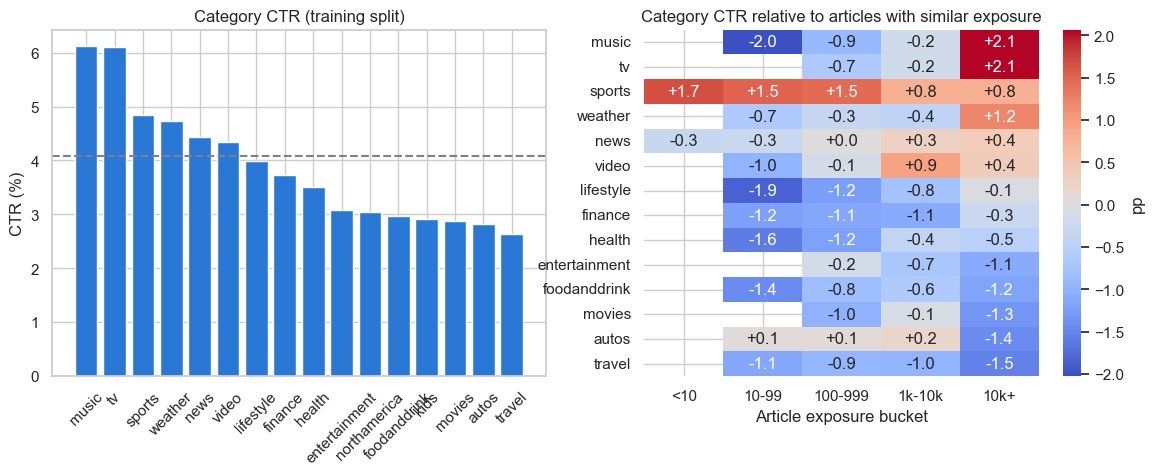

In [5]:
cat_ctr = by_cat[by_cat.exposures > 0].sort_values("ctr", ascending=False)
print(cat_ctr[["shown", "exposures", "ctr"]].round(2))

art["bucket"] = bucket
cell = art.groupby(["category", "bucket"], observed=True).agg(exposures=("exposures", "sum"), clicks=("clicks", "sum")).reset_index()
cell["ctr"] = 100 * cell.clicks / cell.exposures
bucket_avg = cell.groupby("bucket", observed=True).apply(lambda g: 100 * g.clicks.sum() / g.exposures.sum())
cell["dev_pp"] = cell.ctr - cell.bucket.map(bucket_avg).astype(float)
major = cat_ctr[cat_ctr.exposures >= 100_000].index.tolist()
heat = cell[cell.category.isin(major) & (cell.exposures >= 5_000)].pivot(index="category", columns="bucket", values="dev_pp").reindex(major)
print("\nCTR minus the exposure-bucket average (pp):")
print(heat.round(1))

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
ax[0].bar(cat_ctr.index, cat_ctr.ctr)
ax[0].axhline(ctr_all, color="grey", ls="--")
ax[0].tick_params(axis="x", rotation=45)
ax[0].set(ylabel="CTR (%)", title="Category CTR (training split)")
sns.heatmap(heat, cmap="coolwarm", center=0, annot=True, fmt="+.1f", ax=ax[1], cbar_kws={"label": "pp"})
ax[1].set(xlabel="Article exposure bucket", ylabel="", title="Category CTR relative to articles with similar exposure")
plt.savefig(FIG_DIR / "art_03_category_ctr.png", dpi=150, bbox_inches="tight")
plt.show()

# 4. Freshness and time-causal popularity

Article age is measured from the article's **first recorded exposure** in the training window; articles already present in the first hours of the
log are older than that (left-censored, 24% of exposures). Prior popularity is computed strictly before the impression: the article's clicks in all
completed hours before the current one.
* For articles first seen after the log opened, CTR falls from **5.9% in the first hour to about 2.5% after two days**.
* Observed lifespan (first to last exposure) runs from a median of 4 hours (video) to 28 hours (lifestyle) over all shown articles, the
  definition used in the interim report; restricting to articles with at least 10 exposures lengthens every median because single-exposure
  articles have a zero span.
* Prior clicks matter at the head: articles with **1,000+ clicks before the impression** (a third of exposures) are clicked at 6.2%, everything below
  sits near 3%. The relation is not monotonic because articles with no prior click are brand new and benefit from freshness.

**Model Implications**
* `article_age_hours` (from first observed exposure, with a censoring flag) and a category-specific decay; hourly time-causal popularity modelled
  jointly with age. New articles need content and category.

CTR (%) by hours since the article's first recorded exposure:
censored  first seen in window  present at start (censored)
age_bin                                                    
<1h                       5.90                         3.83
1-3h                      4.85                         4.00
3-6h                      4.80                         4.16
6-12h                     4.50                         3.92
12-24h                    4.52                         3.66
24-48h                    4.27                         2.98
48-72h                    2.46                         2.55
>72h                      2.93                         2.61
Exposures on age-censored articles: 24%

Observed lifespan in hours (first to last exposure), shown articles:
               articles  median   p25    p75  median_10plus_exposures
category                                                             
video              1216     3.8   1.1   14.7                      6.1
sports            


CTR by the article's clicks in completed hours before the impression:
         exposures   clicks   ctr  exposure_pct
bin                                            
0          1156697    37766  3.26          1.65
1-9        3850485   123397  3.20          5.48
10-99     12591308   353586  2.81         17.91
100-999   29565746   925119  3.13         42.05
1000+     23150151  1429130  6.17         32.92


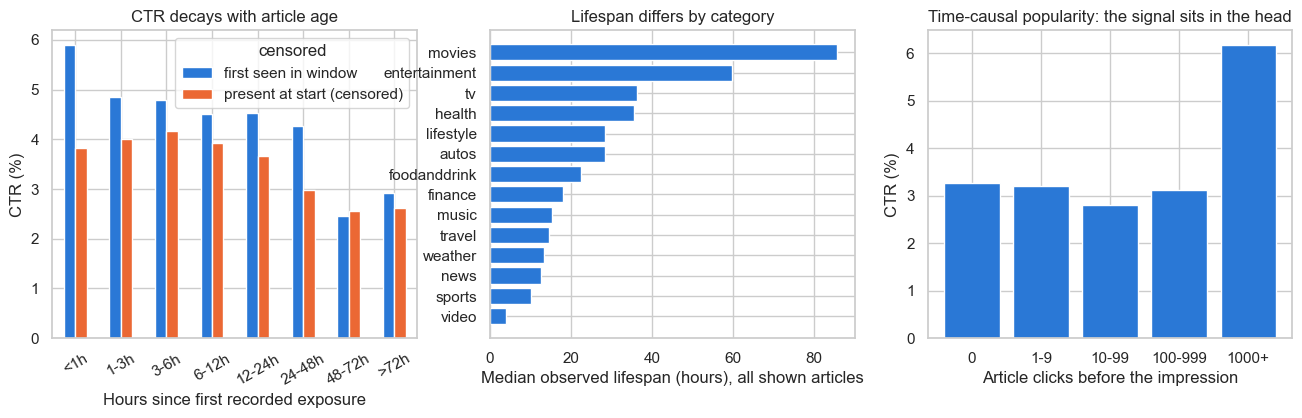

In [6]:
first_seen = news.select("news_code", "first_exposure_train", "last_exposure_train", "exposures_train")
age = (cand.join(first_seen, on="news_code")
       .with_columns(age_h=(pl.col("timestamp") - pl.col("first_exposure_train")).dt.total_seconds() / 3600,
                     censored=pl.col("first_exposure_train") < T0 + pd.Timedelta(hours=6))
       .with_columns(age_bin=pl.col("age_h").cut([1, 3, 6, 12, 24, 48, 72], labels=["<1h", "1-3h", "3-6h", "6-12h", "12-24h", "24-48h", "48-72h", ">72h"]))
       .group_by("censored", "age_bin").agg(exposures=pl.len(), clicks=pl.col("clicked").sum()).to_pandas())
age["ctr"] = 100 * age.clicks / age.exposures
age_tbl = age.pivot(index="age_bin", columns="censored", values="ctr").rename(columns={False: "first seen in window", True: "present at start (censored)"})
print("CTR (%) by hours since the article's first recorded exposure:")
print(age_tbl.round(2))
print(f"Exposures on age-censored articles: {100 * age[age.censored].exposures.sum() / n_exp:.0f}%")

life = tr[tr.exposures_train > 0].assign(life_h=lambda d: (d.last_exposure_train - d.first_exposure_train).dt.total_seconds() / 3600)
lifespan = life.groupby("category").life_h.agg(articles="size", median="median", p25=lambda s: s.quantile(.25), p75=lambda s: s.quantile(.75))
lifespan["median_10plus_exposures"] = life[life.exposures_train >= 10].groupby("category").life_h.median()
lifespan = lifespan[lifespan.articles >= 100].sort_values("median")
print("\nObserved lifespan in hours (first to last exposure), shown articles:")
print(lifespan.round(1))

hour_idx = ((pl.col("timestamp") - pl.lit(T0)).dt.total_seconds() // 3600).cast(pl.Int32)
hourly = (cand.select("news_code", hour_idx.alias("h"), "clicked").group_by("news_code", "h").agg(c=pl.col("clicked").sum()).sort("news_code", "h")
          .with_columns(prior_clicks=pl.col("c").cum_sum().over("news_code") - pl.col("c")))
prior = (cand.select("news_code", hour_idx.alias("h"), "clicked").join(hourly, on=["news_code", "h"])
         .with_columns(bin=pl.col("prior_clicks").cut([0, 9, 99, 999], labels=["0", "1-9", "10-99", "100-999", "1000+"]))
         .group_by("bin").agg(exposures=pl.len(), clicks=pl.col("clicked").sum()).to_pandas().set_index("bin").reindex(["0", "1-9", "10-99", "100-999", "1000+"]))
prior["ctr"] = 100 * prior.clicks / prior.exposures
prior["exposure_pct"] = 100 * prior.exposures / prior.exposures.sum()
print("\nCTR by the article's clicks in completed hours before the impression:")
print(prior.round(2))

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
age_tbl.plot(kind="bar", ax=ax[0], rot=30)
ax[0].set(xlabel="Hours since first recorded exposure", ylabel="CTR (%)", title="CTR decays with article age")
ax[1].barh(lifespan.index, lifespan["median"])
ax[1].set(xlabel="Median observed lifespan (hours), all shown articles", title="Lifespan differs by category")
ax[2].bar(prior.index.astype(str), prior.ctr)
ax[2].set(xlabel="Article clicks before the impression", ylabel="CTR (%)", title="Time-causal popularity: the signal sits in the head")
plt.savefig(FIG_DIR / "art_04_freshness_popularity.png", dpi=150, bbox_inches="tight")
plt.show()

# 5. Cold-start articles in validation and test

An article is cold for the model when it was never shown in the training window. The split is by time, so later days contain new articles.
* On the validation afternoon 95% of exposures still fall on articles shown in train, but on the test day **70% of exposures and 76% of clicks**
  are on articles never shown in train, almost all absent from the training news file altogether.

**Model Implications**
* Candidate generation cannot rely on item ids or in-window popularity alone: on the test day it would miss three quarters of the clicks.
  Content representations and a popularity that updates through the test day are required.

                 status  articles  exposures  clicks      split  exposure_pct  click_pct
         shown in train      5623   12534033  484284 validation          95.0       94.1
in train histories only        30      46783    1793 validation           0.4        0.3
      absent from train      2375     612171   28581 validation           4.6        5.6
         shown in train      3308    4266015  138904       test          30.3       24.2
      absent from train      3658    9661666  431683       test          68.6       75.1
in train histories only        31     157876    4258       test           1.1        0.7


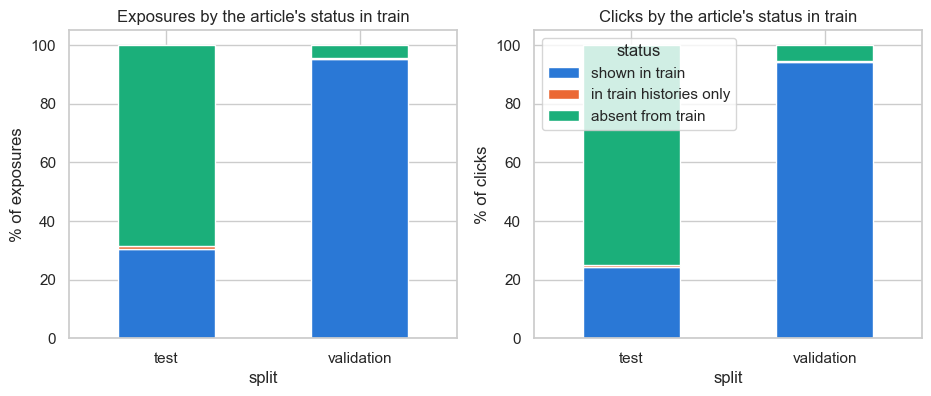

In [7]:
rows = []
for split in ["validation", "test"]:
    cs = (pl.read_parquet(PROCESSED / f"candidates_{split}.parquet", columns=["news_code", "clicked"])
          .join(news.select("news_code", "exposures_train", "in_news_train"), on="news_code", how="left")
          .with_columns(status=pl.when(pl.col("exposures_train") > 0).then(pl.lit("shown in train"))
                                 .when(pl.col("in_news_train")).then(pl.lit("in train histories only")).otherwise(pl.lit("absent from train")))
          .group_by("status").agg(articles=pl.col("news_code").n_unique(), exposures=pl.len(), clicks=pl.col("clicked").sum()).to_pandas())
    cs["split"] = split
    cs["exposure_pct"] = 100 * cs.exposures / cs.exposures.sum()
    cs["click_pct"] = 100 * cs.clicks / cs.clicks.sum()
    rows.append(cs)
cold = pd.concat(rows)
print(cold.round(1).to_string(index=False))

order = ["shown in train", "in train histories only", "absent from train"]
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
cold.pivot(index="split", columns="status", values="exposure_pct")[order].plot(kind="bar", stacked=True, ax=ax[0], rot=0, legend=False)
ax[0].set(ylabel="% of exposures", title="Exposures by the article's status in train")
cold.pivot(index="split", columns="status", values="click_pct")[order].plot(kind="bar", stacked=True, ax=ax[1], rot=0)
ax[1].set(ylabel="% of clicks", title="Clicks by the article's status in train")
plt.savefig(FIG_DIR / "art_05_cold_start_articles.png", dpi=150, bbox_inches="tight")
plt.show()

# 6. Time of day

Volume and engagement by hour of the log clock (timezone undocumented). Because CTR tracks slate length, engagement is measured as **clicks per
impression**; to separate a time effect from who is online, each user's series is also centred on the user's own mean.
* Volume follows a strong daily cycle and is more than twice as high on weekdays as on the weekend.
* Engagement moves far less: within-user clicks per impression stay within **±0.07** of the user's mean (highest around hour 4, lowest at 15),
  and hourly CTR deviations remain within a third of a percentage point whether or not the category mix is held fixed. All categories share the
  same diurnal pattern.

**Model Implications**
* Hour of day is a cheap context feature that mostly improves calibration rather than ranking (it does not separate candidates within a slate).
  Model it as a coarse day-part.

Impressions per day:
      date  impressions  users
2019-11-09       192552 139745
2019-11-10       212343 150620
2019-11-11       464467 301585
2019-11-12       478375 314303
2019-11-13       453494 299936
2019-11-14        96604  83384

By hour of day:
      impression_pct  raw_dev  within_user  ctr_dev_pp
hour                                                  
0              0.794    0.004        0.009      -0.091
1              0.867    0.037        0.033      -0.097
2              1.309    0.033        0.030      -0.112
3              2.327    0.065        0.037      -0.100
4              4.093    0.087        0.048      -0.183
5              6.475    0.074        0.037      -0.111
6              8.035    0.044        0.014      -0.019
7              8.031    0.020        0.005       0.203
8              7.405    0.003        0.000       0.285
9              6.076   -0.020       -0.017       0.295
10             7.408    0.012        0.006       0.229
11             7.592   -0.026 

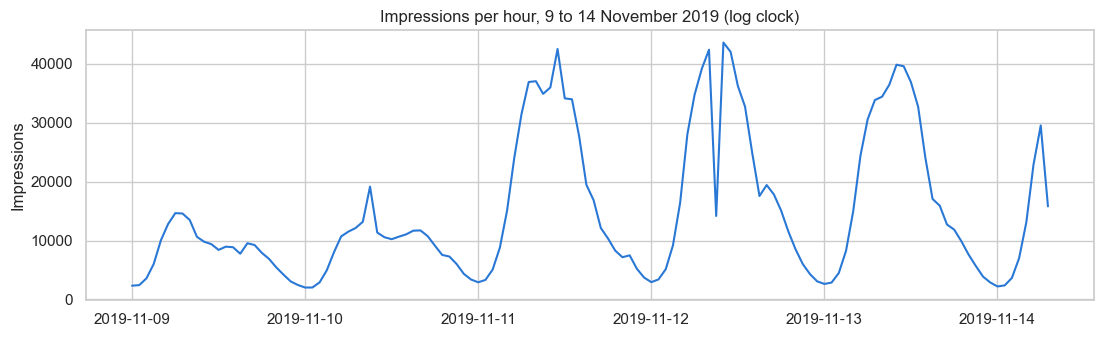

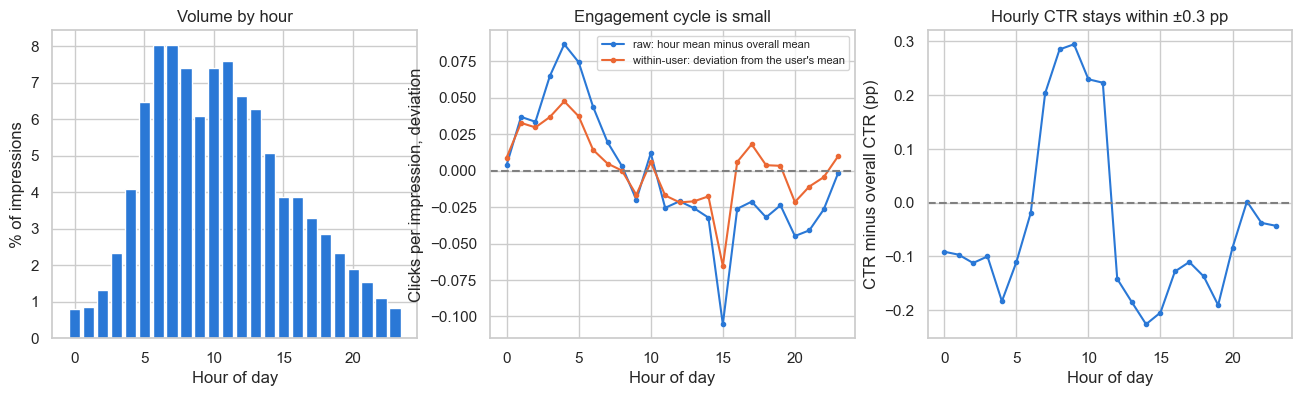

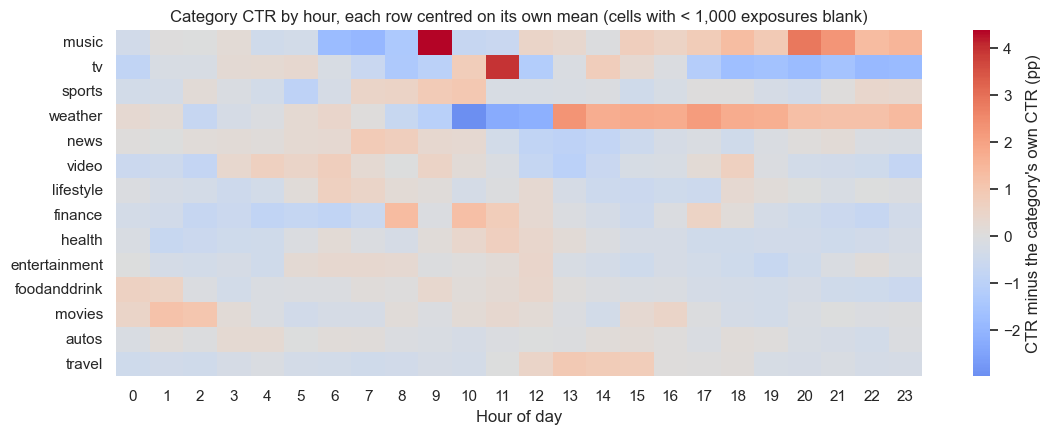

In [8]:
hourly_vol = imp.group_by(pl.col("timestamp").dt.truncate("1h").alias("hour")).len().sort("hour").to_pandas()
daily = imp.group_by(pl.col("timestamp").dt.date().alias("date")).agg(impressions=pl.len(), users=pl.col("user_code").n_unique()).sort("date").to_pandas()
print("Impressions per day:")
print(daily.to_string(index=False))

hod = imp.with_columns(hour=pl.col("timestamp").dt.hour())
multi = hod.filter(pl.len().over("user_code") > 1).with_columns(dev=pl.col("n_clicks") - pl.col("n_clicks").mean().over("user_code"))
by_hour = (hod.group_by("hour").agg(impressions=pl.len(), clicks=pl.col("n_clicks").sum(), exposures=pl.col("slate_len").sum())
           .join(multi.group_by("hour").agg(within_user=pl.col("dev").mean()), on="hour").sort("hour").to_pandas().set_index("hour"))
by_hour["impression_pct"] = 100 * by_hour.impressions / n_imp
by_hour["raw_dev"] = by_hour.clicks / by_hour.impressions - n_clicks / n_imp
by_hour["ctr_dev_pp"] = 100 * by_hour.clicks / by_hour.exposures - ctr_all
print("\nBy hour of day:")
print(by_hour[["impression_pct", "raw_dev", "within_user", "ctr_dev_pp"]].round(3))

ch = (cand.join(cat_map, on="news_code").with_columns(hour=pl.col("timestamp").dt.hour())
      .group_by("hour", "category").agg(exposures=pl.len(), clicks=pl.col("clicked").sum()).to_pandas())
ch["category"] = ch.category.astype(str)
cat_tot = ch.groupby("category")[["exposures", "clicks"]].sum()
cat_tot["ctr"] = 100 * cat_tot.clicks / cat_tot.exposures
ch["dev_pp"] = 100 * ch.clicks / ch.exposures - ch.category.map(cat_tot.ctr)
majors = cat_tot[cat_tot.exposures >= 100_000].sort_values("ctr", ascending=False).index
heat = ch[(ch.exposures >= 1000) & ch.category.isin(majors)].pivot(index="category", columns="hour", values="dev_pp").reindex(majors)

plt.figure(figsize=(13, 3.5))
plt.plot(hourly_vol.hour, hourly_vol["len"])
plt.title("Impressions per hour, 9 to 14 November 2019 (log clock)")
plt.ylabel("Impressions")
plt.savefig(FIG_DIR / "art_06_hourly_volume.png", dpi=150, bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
ax[0].bar(by_hour.index, by_hour.impression_pct)
ax[0].set(xlabel="Hour of day", ylabel="% of impressions", title="Volume by hour")
ax[1].plot(by_hour.index, by_hour.raw_dev, marker="o", ms=3, label="raw: hour mean minus overall mean")
ax[1].plot(by_hour.index, by_hour.within_user, marker="o", ms=3, label="within-user: deviation from the user's mean")
ax[1].axhline(0, color="grey", ls="--")
ax[1].set(xlabel="Hour of day", ylabel="Clicks per impression, deviation", title="Engagement cycle is small")
ax[1].legend(fontsize=8)
ax[2].plot(by_hour.index, by_hour.ctr_dev_pp, marker="o", ms=3)
ax[2].axhline(0, color="grey", ls="--")
ax[2].set(xlabel="Hour of day", ylabel="CTR minus overall CTR (pp)", title="Hourly CTR stays within ±0.3 pp")
plt.savefig(FIG_DIR / "art_06_hour_of_day.png", dpi=150, bbox_inches="tight")
plt.show()

plt.figure(figsize=(13, 4.5))
sns.heatmap(heat, cmap="coolwarm", center=0, cbar_kws={"label": "CTR minus the category's own CTR (pp)"})
plt.title("Category CTR by hour, each row centred on its own mean (cells with < 1,000 exposures blank)")
plt.xlabel("Hour of day")
plt.ylabel("")
plt.savefig(FIG_DIR / "art_06_category_hour_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()

# 7. Time since the user's previous impression

* Two thirds of impressions have a previous visit in the window; the median gap is about 12 hours and 75% of gaps are under a day.
* Clicks per visit peak after a 6 to 24 hour gap and are lowest for immediate continuations and for returns after more than 3 days; within
  users the spread shrinks to about ±0.04 clicks and the long-gap penalty disappears, so much of the raw pattern is user composition.
* The gap is only weakly related to hour of day (Spearman −0.07) and moderately to history length (−0.22).

**Model Implications**
* `hours_since_previous_impression` plus a first-visit indicator is a small session feature; like hour of day it mostly informs calibration.

First impressions (no gap): 35.2%
Gap in hours: {'count': 1229955.0, 'mean': 16.9, 'std': 18.8, 'min': 0.0, '25%': 2.1, '50%': 11.7, '75%': 24.1, '90%': 45.1, 'max': 125.5}
Spearman(gap, hour) = -0.07 | Spearman(gap, history length) = -0.22



Clicks per impression by time since the previous impression:
            impressions  clicks_per_impression  mean_slate_len  within_user  raw_dev
gap                                                                                 
<1 hour          198697                  1.450          34.326       -0.040   -0.090
1-6 hours        313092                  1.548          37.485       -0.037    0.008
6-24 hours       406358                  1.607          38.059        0.038    0.067
1-3 days         286677                  1.508          37.126        0.018   -0.032
>3 days           25131                  1.434          37.404        0.019   -0.106


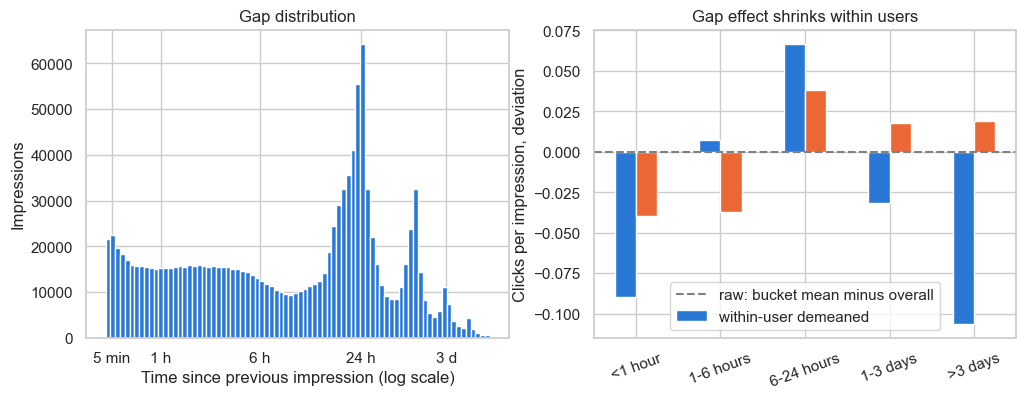

In [9]:
GAPS = ["<1 hour", "1-6 hours", "6-24 hours", "1-3 days", ">3 days"]
g = (imp.sort("user_code", "timestamp").with_columns(gap_h=pl.col("timestamp").diff().over("user_code").dt.total_seconds() / 3600, hour=pl.col("timestamp").dt.hour()))
print(f"First impressions (no gap): {100 * g['gap_h'].is_null().mean():.1f}%")
g = g.drop_nulls("gap_h").with_columns(gap=pl.col("gap_h").cut([1, 6, 24, 72], labels=GAPS))
gap_h = g["gap_h"].to_pandas()
print("Gap in hours:", gap_h.describe(percentiles=[.25, .5, .75, .9]).round(1).to_dict())
print(f"Spearman(gap, hour) = {g.select(pl.corr('gap_h', 'hour', method='spearman')).item():.2f} | Spearman(gap, history length) = {g.select(pl.corr('gap_h', 'history_len', method='spearman')).item():.2f}")

gm = g.filter(pl.len().over("user_code") > 1).with_columns(dev=pl.col("n_clicks") - pl.col("n_clicks").mean().over("user_code"))
tbl = (g.group_by("gap").agg(impressions=pl.len(), clicks_per_impression=pl.col("n_clicks").mean(), mean_slate_len=pl.col("slate_len").mean())
       .join(gm.group_by("gap").agg(within_user=pl.col("dev").mean()), on="gap").to_pandas().set_index("gap").reindex(GAPS))
tbl["raw_dev"] = tbl.clicks_per_impression - g["n_clicks"].mean()
print("\nClicks per impression by time since the previous impression:")
print(tbl.round(3))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].hist(np.log1p(gap_h), bins=80)
ticks = [1 / 12, 1, 6, 24, 72]
ax[0].set_xticks(np.log1p(ticks))
ax[0].set_xticklabels(["5 min", "1 h", "6 h", "24 h", "3 d"])
ax[0].set(xlabel="Time since previous impression (log scale)", ylabel="Impressions", title="Gap distribution")
tbl[["raw_dev", "within_user"]].plot(kind="bar", ax=ax[1], rot=20)
ax[1].axhline(0, color="grey", ls="--")
ax[1].legend(["raw: bucket mean minus overall", "within-user demeaned"])
ax[1].set(xlabel="", ylabel="Clicks per impression, deviation", title="Gap effect shrinks within users")
plt.savefig(FIG_DIR / "art_07_recency_gap.png", dpi=150, bbox_inches="tight")
plt.show()

# Summary

| Finding | Decision |
|---|---|
| Short text, 5% missing abstracts, 12% no entities; subcategory long tail | title-first encoder, abstract mask, entity path optional, embed subcategory |
| 3% of shown articles take 80% of clicks; raw CTR unstable below 100 exposures | prior exposures / clicks / smoothed CTR, never whole-window CTR |
| Category CTR spread survives exposure control | `category` feature, compact encoding, cold-start fallback |
| CTR decays with article age; prior clicks matter at the head | `article_age_hours` + censoring flag; hourly time-causal popularity, modelled jointly with age |
| 70% of test-day exposures (76% of clicks) are on articles unseen in train | content-based candidate generation; popularity must update through the test day |
| Time of day moves volume, not engagement | coarse day-part context feature, calibration not ranking |
| Gap effect small and partly composition | recency feature with first-visit flag, low priority |